In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm



In [2]:
dataset_name = 'Tomsk_py'
data_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/raw/" + dataset_name
corr_str = ''


sites = ['BEK_30m', 'Oblkom_30m', 'IMCES_40m', 'IMCES_30m', 'IMCESmezo_30m', 'Voronino_10m']

df4sites = {}

for site in sites:
    display(site)
    df4site = pd.DataFrame()
    for file in tqdm (glob.glob(data_dir + '/' + site + '/' + 'moment*.csv')):
    #for file in tqdm (glob.glob(data_dir + '/' + site + '/20*' + corr_str + '/' + 'moment*.csv')):
    #for file in tqdm (glob.glob(data_dir + '/' + site + '/20*/' + 'moment*.csv')):
    
        cur_df = pd.read_csv (file, sep = ';') #;, parse_dates=['data'], index_col=['data'])
        cur_df ['data'] = pd.to_datetime(cur_df['data'].apply(lambda s: s.split('+')[0]))
        cur_df.set_index('data', inplace=True)

        cur_df = cur_df.apply(pd.to_numeric, errors='coerce')
        
        if site == 'IMCES_40m' and 'new_rot3' in dataset_name:
            idx = np.where(cur_df.index >= pd.Timestamp(2025,6,17,23,0, 0, tz=0))[0]
            new_index = cur_df.index.values
            new_index[idx] -= pd.Timedelta(hours=9)

            cur_df.index = new_index

            idx = np.where(cur_df.index <= pd.Timestamp(2023,7,1))[0]
            new_index = cur_df.index.values
            new_index[idx] -= pd.Timedelta(hours=7)

            cur_df.index = new_index

        if site == 'IMCES_40m' and 'Tomsk_py' in dataset_name:
            idx = np.where((cur_df.index >= pd.Timestamp(2025,6,17,23,0,0)) & (cur_df.index <= pd.Timestamp(2025,7,14,5,0,0)))[0]
            new_index = cur_df.index.values
            new_index[idx] -= pd.Timedelta(hours=9)

            cur_df.index = new_index

            

        modal_year = pd.Series(cur_df.index.year).mode()[0]
        if str(modal_year) not in os.path.basename(file):
        #if (pd.Timestamp(2024,2,1) in cur_df.index):
             print(file, modal_year)
        
        if 'uz' not in cur_df.columns:
            cur_df['uz'] = np.sqrt (cur_df['uw']**2 + cur_df['vw']**2)
            
        df4site = pd.concat((df4site, cur_df))
        df4site = df4site.sort_index()

    if df4site.shape[0] == 0:
        continue

    #df4site['V_old'] = df4site['V']
    #df4site['V_raw'] = np.sqrt(df4site['Vs']**2 + df4site['Ve']**2)
    #df4site['V'] = np.sqrt(df4site['u']**2 + df4site['v']**2)

    #df4site['rho'] = df4site['tau'] / (df4site['uz'] ** 2)
    #df4site['Cd'] = (df4site['uz'] / df4site['V']) **2
    
    #ustar2u_ratio = df4site['uz'] / df4site['V']
    #display(ustar2u_ratio.quantile(0.99))
    #df4site.loc[ustar2u_ratio > 1, 'Cd'] = np.nan
    
    #df4site = df4site.rename(columns={c: site + '_' + c for c in df4site.columns})
    #df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)        

    df4site.index = df4site.index.tz_localize(None)
    time_arr = pd.date_range(pd.Timestamp(df4site.index.date[0]), pd.Timestamp(df4site.index.date[-1]), freq = '20min') 
    df4site = df4site.resample('20min').last() 
    df4site = df4site.reindex(time_arr)
    
    df4sites[site] = df4site

'BEK_30m'

100%|██████████| 13/13 [00:00<00:00, 13.08it/s]


'Oblkom_30m'

100%|██████████| 25/25 [00:01<00:00, 13.35it/s]


'IMCES_40m'

100%|██████████| 26/26 [00:02<00:00, 12.44it/s]


... (2 outputs left out)

'IMCESmezo_30m'

100%|██████████| 25/25 [00:01<00:00, 13.85it/s]


'Voronino_10m'

100%|██████████| 14/14 [00:01<00:00, 13.05it/s]


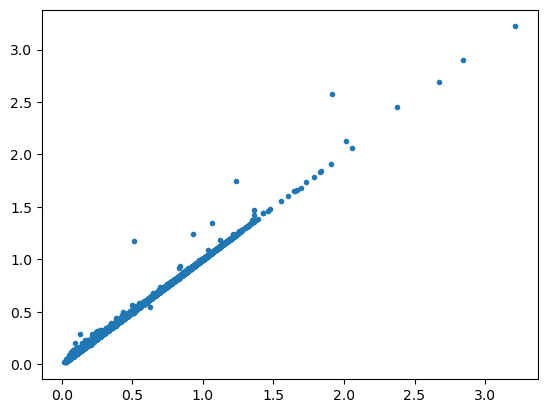

In [3]:
plt.plot(np.sqrt(df4site['ww']), df4site['rmsw'], '.')

C:\Users\mvar9\AppData\Local\Temp\ipykernel_24472\3277051262.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  data = df_is_ok.astype(float).fillna(0).resample('M', label='left').mean()


,BEK_30m,Oblkom_30m,IMCES_40m,IMCES_30m,IMCESmezo_30m,Voronino_10m
2023-11-30,0.000000,0.000000,0.000000,0.000000,0.013889,0.000000
2023-12-31,0.000000,0.000000,0.686828,0.686828,0.995968,0.000000
2024-01-31,0.000000,0.017241,0.999521,1.000000,0.999042,0.000000
2024-02-29,0.000000,0.998208,0.987007,1.000000,0.996864,0.000000
2024-03-31,0.000000,0.953704,0.993981,0.990741,0.991667,0.000000
2024-04-30,0.000000,0.961022,0.998656,1.000000,0.809588,0.000000
2024-05-31,0.000000,1.000000,0.996296,1.000000,1.000000,0.000000
2024-06-30,0.000000,0.794355,0.603495,0.303763,0.992832,0.000000
2024-07-31,0.000000,0.818548,0.992832,0.000000,0.000448,0.000000
2024-08-31,0.000000,1.000000,0.000463,0.000000,0.747222,0.000000


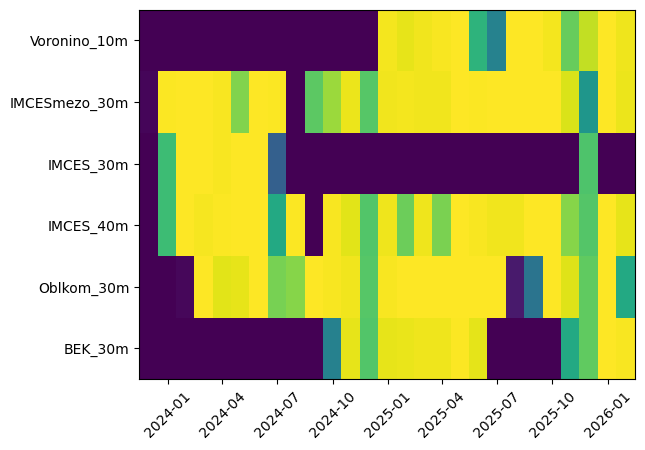

In [4]:
df_is_ok = pd.DataFrame()

for i, site in enumerate (df4sites.keys()):
    df4site = df4sites[site]
    
    is_ok4site = pd.DataFrame(~np.isnan(df4site['H'])).rename(columns = {'H': site})
    df_is_ok = df_is_ok.merge(is_ok4site, how = 'outer', right_index = True, left_index = True)

data = df_is_ok.astype(float).fillna(0).resample('M', label='left').mean()

display(data)

plt.pcolormesh(data.index, data.columns, data.T.to_numpy())
_ = plt.xticks(rotation=45)

export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Tomsk_new_py" + corr_str
os.makedirs(export_dir, exist_ok=True)

plt.savefig(export_dir + "/data_availibility_upd.png", dpi = 300)

In [5]:
df4site = df4sites['Voronino_10m']
((df4site['rmsw'])/(df4site['ustar'])).median()

1.4869521099502667

In [ ]:
df4site = df4sites['Oblkom_30m']
pd.options.plotting.backend = "plotly"
((df4site[['rmsu', 'rmsv', 'rmsw']])/(df4site['ustar'])).plot()

#((df4site['rmsw'])/(df4site['ustar'])).plot()
#plt.plot (psi, (df4site['rmsw']**2)/(df4site['ustar']), 'ok')

KeyError: ('rmsu', 'rmsv', 'rmsw')

In [7]:
# export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Tomsk" + corr_str
# os.makedirs(export_dir, exist_ok=True)

time_shift = pd.Timedelta(7, 'h')

for site in df4sites.keys():
    df4site = df4sites[site]
    #df4site['sigmaW'] = np.sqrt(df4site['ww'])
    #df2export = df4site[['H', 'tau', 'uz', 't', 'r', 'P', 'ro', 'u', 'v', 'w', 'V', 'D', 'alfa']]
    df2export = df4site[['H', 'tau', 'ustar', 't', 'r', 'P', 'ro', 'u', 'v', 'w', 'Vvec', 'vx', 'vy', 'D', 'alfa', 'rmsu', 'rmsv', 'rmsw']]
    df2export = df2export.rename(columns = {'H': 'Qh',
                                            'tau': 'Qtau',
                                            'ustar':'Ustar', 
                                            't': 'T_air',
                                            'r': 'RH_air',
                                            'P': 'P_air',
                                            'ro': 'Rho_air',
                                            'vy':'Wind_V', #'Vs':'Wind_V',
                                            'vx':'Wind_U', #'Ve':'Wind_U',
                                            'w':'Wind_W',
                                            'rmsu': 'Wind_U_std',
                                            'rmsv': 'Wind_V_std',
                                            'rmsw': 'Wind_W_std',
                                            'Vvec':'Wind_vel', #'V':'Wind_vel',
                                            'D':'Wind_dir',
                                            'alfa':'Wind_alpha'})
    df2export['P_air'] = df2export['P_air'] * 1013/760
    df2export.index = df2export.index - time_shift
    df2export.to_csv(export_dir + '/' + site +  '.csv')
